# 14. Non-Hospital Market Share and Verticalization Audit

**Research question:** can non-hospital market-share data identify whether an insurance operator and a provider belong to the same economic group?

**Conclusion for the audited snapshot:** the ownership target is **not identifiable**. Network concentration is observable; common ownership is not. Unknown must not become a negative label.

This notebook examines whether non-hospital market-share data can support a verticalization target, complementing the demand-modeling work in `13_modeling_matrix.ipynb`.

**Population (unchanged by the Medicina de Grupo decision)**: notebooks 09-13 and 15-17 now run on the Medicina de Grupo subset of the treated base (`data_pipeline/08_filter_medicina_de_grupo.ipynb`, Section 4.3.2.8 of the documentation). This notebook is deliberately left out of that change and keeps auditing the full population: under the partner-confirmed rule in that same filter notebook, every Medicina de Grupo operator is already `VERTICALIZED_OPERATOR = 1`, so restricting this audit to Medicina de Grupo would make the question it asks -- can verticalization be identified from market share data -- circular for the one modality it could test. It also feeds nothing downstream.

**Running the notebook**

- Use **Run All** with Python 3.10+ in Jupyter or Google Colab. The notebook contains all analysis functions and checks.
- The only required dataset is the non-hospital market-share CSV. It is partner-supplied confidential data, kept out of version control: place the original file under `data/raw/ans_ambulatorial`, or copy `.env.example` to `.env` at the repository root and fill in `NON_HOSPITAL_MARKET_SHARE_URL` so the notebook downloads it automatically.
- The processed claims file from notebook 04 and outputs from 08–11 are **optional cross-check inputs**. Their absence is reported explicitly and does not prevent the core audit. The public-data pipeline supplies them when the preceding notebooks have been run.
- All results remain in dataframes and inline displays. No report, CSV, chart image or other analysis artifact is written to disk. Save this notebook to retain its displayed results.
- Full ownership validation and independent human team review remain outstanding. A successful execution is technical verification, not ownership validation.

Source field names and legal entity identifiers are preserved for traceability.

## 1. Portable environment and data access

Install only missing dependencies in the current notebook kernel. Existing compatible environments are reused. The core audit needs pandas, NumPy and Matplotlib. Parquet and K-Means dependencies are installed only if the optional historical activity reconstruction is needed. Versions are printed for reproducibility.

The non-hospital market-share CSV is **partner-supplied confidential data**, excluded from version control. Its download link is therefore **not written in this notebook**: it is read from the `NON_HOSPITAL_MARKET_SHARE_URL` variable in a `.env` file at the repository root. The `.env` file is gitignored and never committed; the committed `.env.example` shows the expected variable. To run the notebook, copy `.env.example` to `.env` and fill in the link.

With `FORCE_DOWNLOAD = False`, the notebook first checks the configured local CSV paths, which avoids another download and supports offline execution. If no local copy exists, it downloads the CSV from the configured link into memory. Notebooks 01-13 do not calculate the market-share weights, so a current public ANS registry cannot replace this input. The printed SHA-256 identifies the version used in each run and is asserted against the audited snapshot.

In [1]:
import importlib.util
import importlib.metadata
import subprocess
import sys


def ensure_packages(packages):
    missing = [requirement for module, requirement in packages.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])


ensure_packages({"numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<4",
                 "matplotlib": "matplotlib>=3.8,<4"})
import hashlib
import io
import json
import os
from pathlib import Path
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 20)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | "
      f"Matplotlib {importlib.metadata.version('matplotlib')}")

Python 3.14.2 | pandas 3.0.5 | NumPy 2.5.2 | Matplotlib 3.11.1


In [2]:
# The source link is read from a local .env file, which is gitignored and never committed.
# Copy .env.example to .env at the repository root and fill in NON_HOSPITAL_MARKET_SHARE_URL.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "notebooks").is_dir() and (p / "documents").is_dir()), Path.cwd())
ensure_packages({"dotenv": "python-dotenv>=1,<2"})
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
MARKET_SHARE_URL = os.environ.get("NON_HOSPITAL_MARKET_SHARE_URL", "").strip()

# Local reuse is optional; neither path is specific to the author's computer.
LOCAL_SOURCE_CANDIDATES = [
    ROOT / "data/raw/ans_ambulatorial/market_share_nao_hospitalar_todas_ufs.csv",
    ROOT / "data/raw/non_hospital_market_share.csv",
]
FORCE_DOWNLOAD = False  # True tests the configured URL even when a local copy exists.
REFERENCE_SHA256 = "33473f6690ad73946da19d528ce9e3b58d9a0c4848fe899ce0b705e537bed853"
KEY = ["CD_OPERADORA", "ID_PLANO"]
NORTH = {"AC", "AM", "AP", "PA", "RO", "RR", "TO"}


def read_source_bytes():
    local = next((p for p in LOCAL_SOURCE_CANDIDATES if p.is_file()), None)
    if local is not None and not FORCE_DOWNLOAD:
        return local.read_bytes(), str(local.relative_to(ROOT))
    if not MARKET_SHARE_URL:
        raise FileNotFoundError(
            "NON_HOSPITAL_MARKET_SHARE_URL is not set. Copy .env.example to .env at the "
            "repository root and fill in the link to the non-hospital market-share CSV. "
            "The link is kept out of version control because the file is partner-confidential. "
            "The public ANS pipeline does not produce these calculated weights."
        )
    if not MARKET_SHARE_URL.startswith("https://"):
        raise ValueError("Use an HTTPS download link for the source CSV.")
    if "drive.google.com/" in MARKET_SHARE_URL:
        ensure_packages({"gdown": "gdown>=5,<6"})
        import gdown
        buffer = io.BytesIO()
        file_id_match = re.search(r"/d/([A-Za-z0-9_-]+)|[?&]id=([A-Za-z0-9_-]+)", MARKET_SHARE_URL)
        if not file_id_match:
            raise ValueError("Use a Google Drive file link, not a folder link.")
        file_id = next(value for value in file_id_match.groups() if value)
        result = gdown.download(id=file_id, output=buffer, quiet=True, use_cookies=False)
        if result is None:
            raise RuntimeError("Google Drive download failed. Check that the Drive account has download access.")
        payload = buffer.getvalue()
    else:
        request = urllib.request.Request(MARKET_SHARE_URL, headers={"User-Agent": "NonHospitalAudit/1.0"})
        with urllib.request.urlopen(request, timeout=120) as response:
            payload = response.read()
    if not payload or payload.lstrip().lower().startswith((b"<!doctype html", b"<html")):
        raise ValueError("The source link returned an empty file or an HTML/login page, not the CSV.")
    # No local export/cache: downloaded data stays in memory.
    return payload, "Configured shared source (downloaded in memory)"


payload, source_description = read_source_bytes()
source_sha256 = hashlib.sha256(payload).hexdigest()
df = pd.read_csv(io.BytesIO(payload), dtype=str)
print("Source:", source_description)
print("SHA-256:", source_sha256)
print("Matches original audited snapshot:", source_sha256 == REFERENCE_SHA256)
if source_sha256 != REFERENCE_SHA256:
    print("Different source version: recompute all diagnostics; do not reuse the reference snapshot's counts.")

Source: data\raw\ans_ambulatorial\market_share_nao_hospitalar_todas_ufs.csv
SHA-256: 33473f6690ad73946da19d528ce9e3b58d9a0c4848fe899ce0b705e537bed853
Matches original audited snapshot: True


## 2. Source inventory, provenance and validation

| Source | Verified role | Limitation |
| --- | --- | --- |
| Original CSV under `data/raw/ans_ambulatorial` or configured shared link | Operator–plan–provider records with three precomputed fields | Source weighting program, underlying allocation quantities and reference/availability dates are absent. |
| `documents/extras/data_column_dictionary.md` | Claims dictionary; mentions market-share reference July 2025 | Does not define the three investigated fields. |
| `documents/documentation.md`, sections 4.1 and 4.3 | Partner context and existing modeling decisions | Earlier narrative says North-only and August 2025; the audited CSV spans 27 states and has no date field. |
| Notebooks 01–07 and `scripts/run_pipeline.py` | Public claims ingestion, merge, clinical treatment and exploration | They do not calculate market share. |
| Notebooks 09–10 | Claims activity aggregation and K-Means, with high-event cluster named active | Identifier is claims `ID_PLANO`, not a verified ANS operator registration. |
| Notebooks 11–13 | Municipality-level activity, segmentation and demand-feature proposal | Notebook 13's ATUANTE rule is a roll-up of active municipality pairs, distinct from notebook 10's operator-level split. |
| TAPI business brief | Defines verticalization as operator and specialized service sharing an economic group | Does not provide pair-specific ownership evidence; no runtime dependency. |

The source review covered project documentation, notebook code and saved outputs, local CSVs, and Parquet/ZIP schemas, including files excluded from version control. No ownership map or upstream market-share calculation code was found. The activity comparison follows the methodology documented in notebooks 09–13.

The [official ANS non-hospital directory](https://dadosabertos.ans.gov.br/FTP/PDA/operadoras_e_prestadores_nao_hospitalares/) is a potential upstream registry, not verified lineage for the supplied weights. [ANS owned-network reporting](https://www.gov.br/ans/pt-br/assuntos/operadoras/compromissos-e-interacoes-com-a-ans-1/envio-de-informacoes-1/envio-de-registro-de-rede-propria) describes operator ANS/CNPJ and provider CNPJ/CNES records, including an explicit owned-network response. Such completed, dated records could help supply the missing ownership evidence. No operator-specific RPO data has been obtained. Public references were checked on September 9, 2026.

Identifiers are read as strings to preserve leading zeros. Required missing values, duplicate relationship keys, non-finite weights and invalid percentage ranges stop the analysis. These validations protect the arithmetic; they do not establish ownership or full-market coverage.

In [3]:
required = ["SG_UF", "CD_OPERADORA", "NM_OPERADORA", "ID_PLANO", "CD_PLANO", "CD_CNES",
            "NM_ESTABELECIMENTO_SAUDE", "N_PRESTADORES_NO_GRUPO", "MARKET_SHARE_PCT", "MARKET_SHARE_PCT_INT"]
missing_columns = sorted(set(required) - set(df.columns))
if missing_columns:
    raise ValueError(f"Source CSV is missing required columns: {missing_columns}")
if df.empty or df[required].isna().any().any():
    raise ValueError("The source is empty or required values are missing.")
for column in ["N_PRESTADORES_NO_GRUPO", "MARKET_SHARE_PCT", "MARKET_SHARE_PCT_INT"]:
    df[column] = pd.to_numeric(df[column], errors="raise")
    if not np.isfinite(df[column]).all():
        raise ValueError(f"Non-finite values in {column}.")
if df.duplicated(KEY + ["CD_CNES"]).any():
    raise ValueError("Duplicate operator-plan-provider keys; investigate before aggregating.")
if not df.MARKET_SHARE_PCT.between(0, 100).all():
    raise ValueError("Decimal shares must lie between 0 and 100 percentage points.")
if not df.MARKET_SHARE_PCT_INT.between(0, 100).all() or not np.equal(df.MARKET_SHARE_PCT_INT % 1, 0).all():
    raise ValueError("Integer shares must be whole percentage points between 0 and 100.")
if not (df.N_PRESTADORES_NO_GRUPO > 0).all() or not np.equal(df.N_PRESTADORES_NO_GRUPO % 1, 0).all():
    raise ValueError("Declared provider counts must be positive integers.")
if df.groupby("ID_PLANO").CD_OPERADORA.nunique().max() != 1:
    raise ValueError("An internal plan ID maps to multiple operators; review the source namespace.")
if df.groupby("ID_PLANO").CD_PLANO.nunique().max() != 1 or df.groupby("CD_PLANO").ID_PLANO.nunique().max() != 1:
    raise ValueError("Internal and registered plan IDs are not one-to-one in this source.")
if not np.allclose(df.MARKET_SHARE_PCT * 1000, np.rint(df.MARKET_SHARE_PCT * 1000), rtol=0, atol=1e-7):
    raise ValueError("Source precision exceeds three decimals; adapt the reconstruction before rounding it.")
df["SOURCE_ROW"] = np.arange(2, len(df) + 2)
source_summary = pd.DataFrame({"Measure": ["Relationship rows", "Operators", "Plans", "Distinct providers", "Provider states"],
                               "Value": [len(df), df.CD_OPERADORA.nunique(), df.ID_PLANO.nunique(),
                                         df.CD_CNES.nunique(), df.SG_UF.nunique()]})
display(source_summary)
display(df[["MARKET_SHARE_PCT", "MARKET_SHARE_PCT_INT", "N_PRESTADORES_NO_GRUPO"]].describe(
    percentiles=[.01, .25, .5, .75, .9, .95, .99]))

,Measure,Value
0,Relationship rows,10000
1,Operators,3
2,Plans,46
3,Distinct providers,1365
4,Provider states,27


,MARKET_SHARE_PCT,MARKET_SHARE_PCT_INT,N_PRESTADORES_NO_GRUPO
count,10000.000000,10000.000000,10000.000000
mean,0.458449,0.460000,530.600300
std,1.033628,1.089366,348.537073
min,0.000000,0.000000,14.000000
1%,0.000000,0.000000,34.000000
25%,0.033000,0.000000,198.000000
50%,0.133000,0.000000,584.000000
75%,0.403000,1.000000,953.000000
90%,1.121100,1.000000,953.000000
95%,2.098400,2.000000,953.000000


## 3. Reconstructing the share fields and the meaning of “group”

`MARKET_SHARE_PCT` behaves as percentage points within a plan across states, not as a fraction or a national share among competing operators. The compatible family of formulas is

`s_ijp ≈ 100 × w_ijp / sum(w within plan p)`

The allocation quantity `w` is unknown. It could represent utilization, revenue, capacity or another constructed weight; the file cannot distinguish these possibilities. Exact upstream numerators, denominators and rounding rules cannot be recovered from proportions alone.

- Decimal `1` is consistent with 1%, not 100% or ownership. Decimal zero may be exact or rounded; integer zero can hide a positive source weight.
- `N_PRESTADORES_NO_GRUPO` is checked against distinct CNES per plan. Equality supports a plan-network grouping interpretation, not a corporate group. Counts can vary between plans of the same operator.
- Uniform weighting `100 / N_PRESTADORES_NO_GRUPO` and ordinary nearest-integer rounding are tested rather than assumed.
- The integer reconstruction uses **largest remainders**: floor each share, then allocate the remaining points up to 100 to the largest fractional remainders. Integer thousandths avoid floating-point tie artifacts. This can reproduce the data without proving the original generating code.

A declared count match is only **count-completeness relative to the source field**. It does not prove that the operator supplied every plan or that the declared count itself is correct.

In [4]:
def concentration(values):
    """Conditional distribution of observed source weights, not patient shares.

    Renormalization permits a descriptive HHI even for a partial extract. It
    cannot restore missing providers or make the distribution representative.
    """
    s = pd.Series(values, dtype=float)
    total = s.sum()
    p = s / total if total > 0 else s * np.nan
    return {'SOURCE_PCT_TOTAL': total, 'N_OBSERVED': len(s),
            'SOURCE_PCT_MAX': s.max(), 'OBSERVED_MAX': p.max(),
            'OBSERVED_TOP3': p.nlargest(3).sum(min_count=1),
            'OBSERVED_TOP5': p.nlargest(5).sum(min_count=1),
            'HHI_OBSERVED': (p ** 2).sum(min_count=1)}

def plan_metrics(d):
    result, reconstructed = [], []
    for key, g in d.groupby(KEY, sort=True):
        # Work in thousandths to avoid binary float tie artifacts.
        milli = np.rint(g.MARKET_SHARE_PCT * 1000).astype(int)
        floor, remainder = milli // 1000, milli % 1000
        gap = 100 - int(floor.sum())
        order = remainder.sort_values(ascending=False, kind='stable').index
        prediction = floor.copy()
        if 0 <= gap <= len(g):
            prediction.loc[order[:gap]] += 1
        observed_up = g.MARKET_SHARE_PCT_INT - floor
        valid_floor_ceil = observed_up.isin([0, 1]).all()
        # Ties at the allocation cutoff cannot be resolved from 3-decimal input.
        selected = remainder[observed_up == 1]
        unselected = remainder[observed_up == 0]
        ordered = selected.empty or unselected.empty or selected.min() >= unselected.max()
        compatible = valid_floor_ceil and int(g.MARKET_SHARE_PCT_INT.sum()) == 100 and ordered
        count = g.CD_CNES.nunique()
        nvalues = g.N_PRESTADORES_NO_GRUPO.nunique()
        expected = int(g.N_PRESTADORES_NO_GRUPO.iloc[0])
        complete = nvalues == 1 and count == expected
        r = dict(zip(KEY, key)) | concentration(g.MARKET_SHARE_PCT)
        r.update(N_PRESTADORES=count, N_PRESTADORES_NO_GRUPO=expected,
                 GROUP_COUNT_DISTINCT=nvalues, COUNT_COMPLETE=complete,
                 COUNT_COVERAGE=count / expected, INT_SUM=int(g.MARKET_SHARE_PCT_INT.sum()),
                 INTEGER_HAMILTON_COMPATIBLE=bool(compatible),
                 INTEGER_STABLE_TIE_MATCHES=int((prediction == g.MARKET_SHARE_PCT_INT).sum()),
                 UNIFORM_SHARE_MATCH_ROWS=int(np.isclose(g.MARKET_SHARE_PCT, 100 / expected, atol=.000501, rtol=0).sum()))
        r['HHI_COMPLETE_PLAN'] = r['HHI_OBSERVED'] if complete else np.nan
        result.append(r)
        reconstructed.append(pd.DataFrame({'SOURCE_ROW': g.SOURCE_ROW, 'FLOOR_PCT': floor,
                                           'REMAINDER_THOUSANDTHS': remainder,
                                           'INT_STABLE_TIE_CANDIDATE': prediction,
                                           'INT_SOURCE': g.MARKET_SHARE_PCT_INT}))
    return pd.DataFrame(result), pd.concat(reconstructed, ignore_index=True)

In [5]:
plan_diagnostics, integer_reconstruction = plan_metrics(df)
structural_tests = pd.DataFrame([
    ["Group count matches distinct observed plan providers", int(plan_diagnostics.COUNT_COMPLETE.sum()), len(plan_diagnostics), "Plan-network interpretation; not corporate control"],
    ["Uniform share: 100 / declared provider count", int(plan_diagnostics.UNIFORM_SHARE_MATCH_ROWS.sum()), len(df), "Check before interpreting count as the share denominator"],
    ["Nearest integer, half-up", int(np.equal(np.floor(df.MARKET_SHARE_PCT + .5), df.MARKET_SHARE_PCT_INT).sum()), len(df), "Distinguishes simple rounding from apportionment"],
    ["Largest remainder compatible, allowing cutoff ties", int(plan_diagnostics.INTEGER_HAMILTON_COMPATIBLE.sum()), len(plan_diagnostics), "Compatibility only; no proven source lineage"],
    ["Stable source-order integer reconstruction", int(plan_diagnostics.INTEGER_STABLE_TIE_MATCHES.sum()), len(df), "Exact reconstruction is not an ownership signal"],
], columns=["Test", "Matching observations", "Total observations", "Interpretation"])
display(structural_tests)
display(plan_diagnostics)
incomplete_plans = plan_diagnostics.loc[~plan_diagnostics.COUNT_COMPLETE,
    KEY + ["N_PRESTADORES", "N_PRESTADORES_NO_GRUPO", "SOURCE_PCT_TOTAL", "INT_SUM", "COUNT_COVERAGE"]]
display(Markdown("**Plans inconsistent with their declared provider count:**"))
display(incomplete_plans)
print("Decimal zeros:", int(df.MARKET_SHARE_PCT.eq(0).sum()))
print("Positive decimal shares displayed as integer zero:", int((df.MARKET_SHARE_PCT.gt(0) & df.MARKET_SHARE_PCT_INT.eq(0)).sum()))
# Keep concrete records visible without dumping the full confidential input.
display(df.loc[df.MARKET_SHARE_PCT.nlargest(5).index,
               KEY + ["CD_CNES", "N_PRESTADORES_NO_GRUPO", "MARKET_SHARE_PCT", "MARKET_SHARE_PCT_INT"]])

,Test,Matching observations,Total observations,Interpretation
0,Group count matches distinct observed plan pro...,45,46,Plan-network interpretation; not corporate con...
1,Uniform share: 100 / declared provider count,10,10000,Check before interpreting count as the share d...
2,"Nearest integer, half-up",9245,10000,Distinguishes simple rounding from apportionment
3,"Largest remainder compatible, allowing cutoff ...",46,46,Compatibility only; no proven source lineage
4,Stable source-order integer reconstruction,10000,10000,Exact reconstruction is not an ownership signal


,CD_OPERADORA,ID_PLANO,SOURCE_PCT_TOTAL,N_OBSERVED,SOURCE_PCT_MAX,OBSERVED_MAX,OBSERVED_TOP3,OBSERVED_TOP5,HHI_OBSERVED,N_PRESTADORES,N_PRESTADORES_NO_GRUPO,GROUP_COUNT_DISTINCT,COUNT_COMPLETE,COUNT_COVERAGE,INT_SUM,INTEGER_HAMILTON_COMPATIBLE,INTEGER_STABLE_TIE_MATCHES,UNIFORM_SHARE_MATCH_ROWS,HHI_COMPLETE_PLAN
0,000477,18858067,100.000,953,0.982,0.009820,0.025350,0.039910,0.002591,953,953,1,True,1.000000,100,True,953,2,0.002591
1,000477,18858081,99.990,953,1.041,0.010411,0.028193,0.044904,0.002842,953,953,1,True,1.000000,100,True,953,1,0.002842
2,000477,18860719,100.003,198,3.446,0.034459,0.093627,0.147126,0.013264,198,198,1,True,1.000000,100,True,198,0,0.013264
3,000477,18860729,99.995,205,3.700,0.037002,0.103325,0.161808,0.013000,205,205,1,True,1.000000,100,True,205,0,0.013000
4,000477,18860748,99.995,953,1.819,0.018191,0.039562,0.057153,0.003045,953,953,1,True,1.000000,100,True,953,4,0.003045
5,000477,18860758,100.000,198,3.944,0.039440,0.104220,0.165580,0.013687,198,198,1,True,1.000000,100,True,198,0,0.013687
6,000477,18860768,99.999,191,3.522,0.035220,0.100971,0.159102,0.015557,191,191,1,True,1.000000,100,True,191,0,0.015557
7,000515,1331902,99.997,189,6.605,0.066052,0.127984,0.181525,0.015886,189,189,1,True,1.000000,100,True,189,0,0.015886
8,000582,1332115,100.000,55,6.974,0.069740,0.200670,0.318340,0.038839,55,55,1,True,1.000000,100,True,55,0,0.038839
9,000582,1332117,99.999,57,7.546,0.075461,0.186622,0.283363,0.034001,57,57,1,True,1.000000,100,True,57,0,0.034001


**Plans inconsistent with their declared provider count:**

,CD_OPERADORA,ID_PLANO,N_PRESTADORES,N_PRESTADORES_NO_GRUPO,SOURCE_PCT_TOTAL,INT_SUM,COUNT_COVERAGE
45,000582,16192433,227,584,84.558,100,0.388699


Decimal zeros: 234
Positive decimal shares displayed as integer zero: 6966


,CD_OPERADORA,ID_PLANO,CD_CNES,N_PRESTADORES_NO_GRUPO,MARKET_SHARE_PCT,MARKET_SHARE_PCT_INT
7094,000582,15727741,2089564,14,20.017,20
5358,000582,1332431,3953238,33,17.093,17
7095,000582,15727741,2077477,14,14.887,15
5359,000582,1332431,0002275,33,14.542,14
5391,000582,1332433,2515431,34,14.094,14


**Reference snapshot interpretation.** The original 10,000-row file covers 3 operators, 46 plans and 1,365 providers. In 45 plans the declared count matches observed providers. The final plan `16192433` contains 227 of 584 declared providers and 84.558 percentage points; its integer shares nevertheless total 100. Missing low weights can have integer zero, so a sum of 100 in the integer field does not prove completeness. The exact row limit suggests a truncated export but does not establish its cause.

Largest-remainder allocation with stable source order reproduces all 10,000 integer values. In plan `1332117`, displayed remainders of .505 occur for both 3.505 and 0.505; source order reproduces the allocation of the extra point. This is a reconstruction of the observed snapshot, not a verified description of upstream software. The printed hash above identifies whether the current run uses that snapshot.

## 4. Network concentration, geography and identity quality

For observed weights within a plan or geographic subset, set `p_j = s_j / sum(s)` and compute `HHI = sum(p_j**2)`, maximum share and top-three/top-five shares. HHI is on a **0–1 scale**. These metrics describe concentration of the supplied allocation weights, whose economic basis remains unknown. They are not established patient shares or ownership intensity.

Keep the original percentage-point total alongside every regional normalization: renormalizing North or UF rows changes the denominator and cannot recover missing providers. Count-incomplete plans are retained for diagnostics and excluded from the operator scenario below.

Providers are deduplicated by CNES for network counts. Repeated appearances across plans are expected. Name changes are reported but never used to infer ownership or classify an establishment as hospital/non-hospital. The filename alone is not a validated facility-type filter.

,N_PRESTADORES,OBSERVED_MAX,HHI_OBSERVED
N_PRESTADORES,1.000000,-0.898906,-0.947309
OBSERVED_MAX,-0.898906,1.000000,0.960870
HHI_OBSERVED,-0.947309,0.960870,1.000000


Providers appearing under multiple operators: 484
Providers with multiple supplied names: 411
Providers with conflicting supplied states: 0


,SG_UF,CD_OPERADORA,NM_OPERADORA,ID_PLANO,CD_PLANO,CD_CNES,NM_ESTABELECIMENTO_SAUDE,CD_MUNICIPIO,NM_MUNICIPIO,NM_REGIAO,N_PRESTADORES_NO_GRUPO,MARKET_SHARE_PCT,MARKET_SHARE_PCT_INT,SOURCE_ROW,RANK_WITHIN_PLAN
0,GO,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,2340712,HOSP STA TEREZINHA LTDA,521880,RIO VERDE,CENTRO-OESTE,953,0.982,1,2,1
1,RJ,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,2288907,APMIR ASS PROT MAT INF DE RESENDE,330420,RESENDE,SUDESTE,953,0.786,1,3,2
2,MG,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,2205440,FUNDACAO SAO FRANCISCO XAVIER,313130,IPATINGA,SUDESTE,953,0.767,1,4,3
3,PB,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,3012611,CASA DE SAUDE BOM JESUS LTDA,251620,SOUSA,NORDESTE,953,0.737,1,5,4
4,RJ,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,7436734,C M M A CENT MED MOISES ABRAAO LTDA,330200,ITAGUAI,SUDESTE,953,0.719,1,6,5
953,MG,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858081,503297251,2115891,INST MATERNO INF DE MG,314480,NOVA LIMA,SUDESTE,953,1.041,1,955,1
954,RS,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858081,503297251,3006522,ASSOC HOSPITALAR MOINHOS DE VENTO,431490,PORTO ALEGRE,SUL,953,0.895,1,956,2
955,SP,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858081,503297251,2071568,FUND ZERBINI,355030,SAO PAULO,SUDESTE,953,0.883,1,957,3
956,SC,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858081,503297251,2491249,HOSP SANTA CRUZ DE CANOINHAS,420380,CANOINHAS,SUL,953,0.851,1,958,4
957,SP,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858081,503297251,2078430,HOSP DAS CLINICAS FERNANDOPOLISSC,351550,FERNANDOPOLIS,SUDESTE,953,0.820,1,959,5


,CD_OPERADORA,ID_PLANO,SOURCE_PCT_TOTAL,N_OBSERVED,SOURCE_PCT_MAX,OBSERVED_MAX,OBSERVED_TOP3,OBSERVED_TOP5,HHI_OBSERVED
0,000477,18858067,3.539,35,0.380,0.107375,0.284826,0.433456,0.058058
1,000477,18858081,2.972,35,0.439,0.147712,0.349933,0.473755,0.068633
2,000477,18860748,2.820,35,0.463,0.164184,0.361702,0.524823,0.079247
3,000515,1331902,3.365,7,2.646,0.786330,0.904606,0.985438,0.629220
4,000582,1332115,2.567,5,1.419,0.552785,0.980522,1.000000,0.418891
5,000582,1332117,9.400,5,3.322,0.353404,0.784894,1.000000,0.249039
6,000582,1332119,17.285,5,8.493,0.491351,0.928319,1.000000,0.341032
7,000582,1332121,6.731,5,2.513,0.373347,0.864062,1.000000,0.280525
8,000582,1332123,2.784,5,1.316,0.472701,0.927083,1.000000,0.334346
9,000582,1332125,2.425,5,1.458,0.601237,0.938969,1.000000,0.443170


,CD_OPERADORA,ID_PLANO,SG_UF,SOURCE_PCT_TOTAL,N_OBSERVED,SOURCE_PCT_MAX,OBSERVED_MAX,OBSERVED_TOP3,OBSERVED_TOP5,HHI_OBSERVED
0,000477,18858067,AC,0.006,1,0.006,1.000000,1.000000,1.000000,1.000000
1,000477,18858067,AL,1.503,11,0.537,0.357285,0.761810,0.873586,0.220385
2,000477,18858067,AM,0.389,3,0.267,0.686375,1.000000,1.000000,0.560273
3,000477,18858067,AP,0.090,2,0.078,0.866667,1.000000,1.000000,0.768889
4,000477,18858067,BA,6.521,74,0.515,0.078976,0.206257,0.289679,0.033732
5,000477,18858067,CE,1.977,17,0.648,0.327769,0.566515,0.711179,0.157223
6,000477,18858067,DF,2.581,19,0.523,0.202635,0.466098,0.651685,0.110838
7,000477,18858067,ES,1.984,14,0.545,0.274698,0.610383,0.759577,0.152003
8,000477,18858067,GO,5.933,44,0.982,0.165515,0.298163,0.404011,0.057413
9,000477,18858067,MA,0.946,13,0.410,0.433404,0.764271,0.914376,0.268182


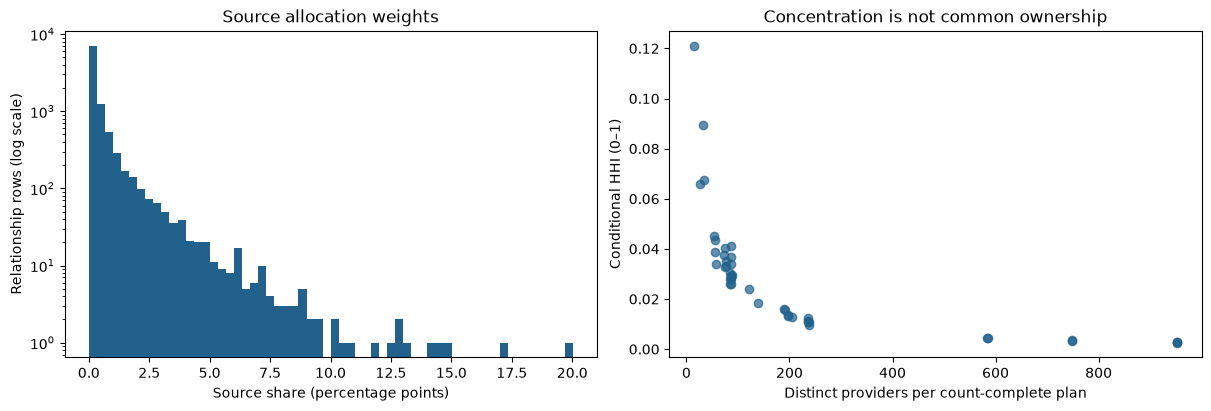

In [6]:
top_providers = df.sort_values(KEY + ["MARKET_SHARE_PCT", "CD_CNES"], ascending=[True, True, False, True]).copy()
top_providers["RANK_WITHIN_PLAN"] = top_providers.groupby(KEY).cumcount() + 1
top_providers = top_providers.loc[top_providers.RANK_WITHIN_PLAN <= 5]
plan_state_concentration = pd.DataFrame([
    dict(zip(KEY + ["SG_UF"], key)) | concentration(group.MARKET_SHARE_PCT)
    for key, group in df.groupby(KEY + ["SG_UF"])
])
plan_north_concentration = pd.DataFrame([
    dict(zip(KEY, key)) | concentration(group.MARKET_SHARE_PCT)
    for key, group in df.loc[df.SG_UF.isin(NORTH)].groupby(KEY)
])
provider_identity = df.groupby("CD_CNES").agg(
    N_OPERATORS=("CD_OPERADORA", "nunique"), N_PLANS=("ID_PLANO", "nunique"),
    N_NAMES=("NM_ESTABELECIMENTO_SAUDE", "nunique"), N_STATES=("SG_UF", "nunique")
).reset_index()
complete_plans = plan_diagnostics.loc[plan_diagnostics.COUNT_COMPLETE]
correlations = complete_plans[["N_PRESTADORES", "OBSERVED_MAX", "HHI_OBSERVED"]].corr(method="spearman")
display(correlations)
print("Providers appearing under multiple operators:", int(provider_identity.N_OPERATORS.gt(1).sum()))
print("Providers with multiple supplied names:", int(provider_identity.N_NAMES.gt(1).sum()))
print("Providers with conflicting supplied states:", int(provider_identity.N_STATES.gt(1).sum()))
display(top_providers.head(15))
display(plan_north_concentration.head(10))
display(plan_state_concentration.head(10))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].hist(df.MARKET_SHARE_PCT, bins=60, color="#21618c")
axes[0].set(yscale="log", xlabel="Source share (percentage points)", ylabel="Relationship rows (log scale)", title="Source allocation weights")
axes[1].scatter(complete_plans.N_PRESTADORES, complete_plans.HHI_OBSERVED, alpha=.7, color="#21618c")
axes[1].set(xlabel="Distinct providers per count-complete plan", ylabel="Conditional HHI (0–1)", title="Concentration is not common ownership")
plt.show()

The reference snapshot has 484 providers in more than one operator's network and 69 in all three. Multiple memberships neither prove that those operators are independent economic groups nor exclude ownership by one of them. They demonstrate why membership alone is insufficient.

The count-to-HHI Spearman coefficient in the original count-complete plans is approximately −0.947. Smaller networks mechanically constrain HHI (`HHI >= 1/n`). Plans also share providers and belong to only three operators, so this correlation is not ownership validation and does not justify treating plans as independent observations. No ownership p-value, predictive accuracy or AUC is calculated without ground-truth ownership labels.

## 5. Candidate targets and evidence levels

| Evidence | Required interpretation | Application here |
| --- | --- | --- |
| `DIRECT` | Dated authoritative evidence of common control, or an explicit sufficiently scoped negative, linked to the exact entities | No verified records. |
| `STRONG_PROXY` | Independently corroborated structural relationship validated against direct labels, with an explicit project decision allowing it | No such validation. |
| `WEAK_PROXY` | Network membership, concentration, count or activity pattern | Concentration diagnostics only. |
| `UNKNOWN` | Missing, conflicting, unlinked or incomplete ownership evidence | Every ownership candidate. |

`EVIDENCE_LEVEL` refers to ownership; `PROXY_EVIDENCE_LEVEL` separately describes concentration. `CONFIDENCE = NOT_ESTIMABLE` is not a numerical probability.

| Candidate | Proposed rule if evidence becomes available | Current result |
| --- | --- | --- |
| `VERTICALIZED_PROVIDER` | Operator–provider–date pair: 1 for verified shared control, 0 for verified distinct control, otherwise NA | NA |
| `VERTICALIZED_OPERATOR` | At least one verified owned in-scope provider → 1; explicit valid negative or complete all-negative review → 0; otherwise NA | NA |
| `VERTICALIZATION_INTENSITY` | Verified owned providers / complete dated in-scope provider universe | NA |
| `VERTICALIZED_MARKET_SHARE` | Validated allocation mass of verified owned providers / total validated mass | NA |
| `VERTICALIZATION_TARGET` | Evidence-backed Verticalized / Non-verticalized / Unknown | Unknown |

A provider target is relative to an operator, not a global property of a provider. A non-hospital North-region negative could not establish that the operator has no owned hospitals or providers elsewhere.

**Operator concentration scenario:** normalize each count-complete positive-mass plan, then average its provider weights equally across observed eligible plans. An absent provider contributes zero only within those observed plans. No beneficiary or patient mixture is available; equal plan weighting is an explicit descriptive scenario. It is not national operator market share.

In [7]:
def aggregate_operators(d, plans):
    rows, provider_weights = [], []
    for operator, g in d.groupby('CD_OPERADORA', sort=True):
        # Equal plan weights are an explicit scenario, not estimated patient mix.
        # Exclude count-incomplete plans from this scenario; retain them in audit.
        complete_ids = set(plans.loc[(plans.CD_OPERADORA == operator) & plans.COUNT_COMPLETE & plans.SOURCE_PCT_TOTAL.gt(0), 'ID_PLANO'])
        c = g[g.ID_PLANO.isin(complete_ids)].copy()
        c['P'] = c.MARKET_SHARE_PCT / c.groupby('ID_PLANO').MARKET_SHARE_PCT.transform('sum')
        weights = c.groupby('CD_CNES').P.sum() / len(complete_ids)
        r = {'CD_OPERADORA': operator, 'NM_OPERADORA': g.NM_OPERADORA.iloc[0],
             'N_PRESTADORES': g.CD_CNES.nunique(), 'N_PLANS': g.ID_PLANO.nunique(),
             'N_COMPLETE_PLANS': len(complete_ids),
             # A scalar plan count has no valid operator-level interpretation.
             'N_PRESTADORES_NO_GRUPO': np.nan,
             'PLAN_GROUP_COUNT_VALUES': '|'.join(map(str, sorted(g.N_PRESTADORES_NO_GRUPO.unique()))),
             'PLAN_GROUP_COUNT_MIN': g.N_PRESTADORES_NO_GRUPO.min(),
             'PLAN_GROUP_COUNT_MAX': g.N_PRESTADORES_NO_GRUPO.max(),
             'SOURCE_PCT_SUM_ACROSS_PLAN_ROWS': g.MARKET_SHARE_PCT.sum(),
             'MARKET_SHARE_TOTAL': weights.sum() if len(weights) else np.nan,
             'MARKET_SHARE_MAX': weights.max(), 'MARKET_SHARE_TOP3': weights.nlargest(3).sum(min_count=1),
             'MARKET_SHARE_TOP5': weights.nlargest(5).sum(min_count=1), 'HHI_EQUAL_COMPLETE_PLAN': (weights ** 2).sum(min_count=1),
             'N_NORTH_PROVIDERS': g.loc[g.SG_UF.isin(NORTH), 'CD_CNES'].nunique(),
             'VERTICALIZED_OPERATOR': pd.NA, 'VERTICALIZATION_INTENSITY': np.nan,
             'VERTICALIZED_MARKET_SHARE': np.nan, 'VERTICALIZATION_TARGET': 'Unknown',
             'EVIDENCE_LEVEL': 'UNKNOWN', 'PROXY_EVIDENCE_LEVEL': 'WEAK_PROXY',
             'EVIDENCE_SOURCE': 'Non-hospital extract; no dated ownership mapping',
             'CONFIDENCE': 'NOT_ESTIMABLE', 'CANDIDATE_STATUS': 'PROXY_ONLY'}
        rows.append(r)
        provider_weights.extend({'CD_OPERADORA': operator, 'CD_CNES': p, 'EQUAL_COMPLETE_PLAN_WEIGHT': w} for p, w in weights.items())
    a = pd.DataFrame(rows)
    return a, pd.DataFrame(provider_weights, columns=['CD_OPERADORA', 'CD_CNES', 'EQUAL_COMPLETE_PLAN_WEIGHT'])

In [8]:
provider_plan_candidates = df.merge(plan_diagnostics[KEY + ["COUNT_COMPLETE", "SOURCE_PCT_TOTAL"]], on=KEY, validate="many_to_one")
provider_plan_candidates["OBSERVED_PLAN_WEIGHT"] = provider_plan_candidates.MARKET_SHARE_PCT.div(provider_plan_candidates.SOURCE_PCT_TOTAL.replace(0, np.nan))
provider_plan_candidates["VERTICALIZED_PROVIDER"] = pd.array([pd.NA] * len(df), dtype="Int64")
provider_plan_candidates["VERTICALIZATION_TARGET"] = "Unknown"
provider_plan_candidates["EVIDENCE_LEVEL"] = "UNKNOWN"
provider_plan_candidates["PROXY_EVIDENCE_LEVEL"] = "WEAK_PROXY"
provider_plan_candidates["CONFIDENCE"] = "NOT_ESTIMABLE"
provider_plan_candidates["EVIDENCE_SOURCE"] = "Network membership and allocation weights; no dated ownership evidence"
provider_operator_candidates = df.groupby(["CD_OPERADORA", "CD_CNES"]).agg(N_PLANS=("ID_PLANO", "nunique")).reset_index()
provider_operator_candidates["VERTICALIZED_PROVIDER"] = pd.array([pd.NA] * len(provider_operator_candidates), dtype="Int64")
provider_operator_candidates["VERTICALIZATION_TARGET"] = "Unknown"
provider_operator_candidates["EVIDENCE_LEVEL"] = "UNKNOWN"
operator_audit, operator_provider_weights = aggregate_operators(df, plan_diagnostics)
# No invented ownership value is allowed into any candidate level.
operator_audit["ACTIVITY_STATUS"] = "UNKNOWN_UNLINKED"
operator_audit["ACTIVITY_SOURCE"] = "Awaiting a verified claims-to-ANS operator crosswalk"
display(provider_plan_candidates.head(5))
display(operator_audit)

,SG_UF,CD_OPERADORA,NM_OPERADORA,ID_PLANO,CD_PLANO,CD_CNES,NM_ESTABELECIMENTO_SAUDE,CD_MUNICIPIO,NM_MUNICIPIO,NM_REGIAO,...,SOURCE_ROW,COUNT_COMPLETE,SOURCE_PCT_TOTAL,OBSERVED_PLAN_WEIGHT,VERTICALIZED_PROVIDER,VERTICALIZATION_TARGET,EVIDENCE_LEVEL,PROXY_EVIDENCE_LEVEL,CONFIDENCE,EVIDENCE_SOURCE
0,GO,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,2340712,HOSP STA TEREZINHA LTDA,521880,RIO VERDE,CENTRO-OESTE,...,2,True,100.0,0.00982,<NA>,Unknown,UNKNOWN,WEAK_PROXY,NOT_ESTIMABLE,Network membership and allocation weights; no ...
1,RJ,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,2288907,APMIR ASS PROT MAT INF DE RESENDE,330420,RESENDE,SUDESTE,...,3,True,100.0,0.00786,<NA>,Unknown,UNKNOWN,WEAK_PROXY,NOT_ESTIMABLE,Network membership and allocation weights; no ...
2,MG,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,2205440,FUNDACAO SAO FRANCISCO XAVIER,313130,IPATINGA,SUDESTE,...,4,True,100.0,0.00767,<NA>,Unknown,UNKNOWN,WEAK_PROXY,NOT_ESTIMABLE,Network membership and allocation weights; no ...
3,PB,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,3012611,CASA DE SAUDE BOM JESUS LTDA,251620,SOUSA,NORDESTE,...,5,True,100.0,0.00737,<NA>,Unknown,UNKNOWN,WEAK_PROXY,NOT_ESTIMABLE,Network membership and allocation weights; no ...
4,RJ,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,18858067,503296252,7436734,C M M A CENT MED MOISES ABRAAO LTDA,330200,ITAGUAI,SUDESTE,...,6,True,100.0,0.00719,<NA>,Unknown,UNKNOWN,WEAK_PROXY,NOT_ESTIMABLE,Network membership and allocation weights; no ...


,CD_OPERADORA,NM_OPERADORA,N_PRESTADORES,N_PLANS,N_COMPLETE_PLANS,N_PRESTADORES_NO_GRUPO,PLAN_GROUP_COUNT_VALUES,PLAN_GROUP_COUNT_MIN,PLAN_GROUP_COUNT_MAX,SOURCE_PCT_SUM_ACROSS_PLAN_ROWS,...,VERTICALIZATION_INTENSITY,VERTICALIZED_MARKET_SHARE,VERTICALIZATION_TARGET,EVIDENCE_LEVEL,PROXY_EVIDENCE_LEVEL,EVIDENCE_SOURCE,CONFIDENCE,CANDIDATE_STATUS,ACTIVITY_STATUS,ACTIVITY_SOURCE
0,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,953,7,7,NaN,191|198|205|953,191,953,699.982,...,NaN,NaN,Unknown,UNKNOWN,WEAK_PROXY,Non-hospital extract; no dated ownership mapping,NOT_ESTIMABLE,PROXY_ONLY,UNKNOWN_UNLINKED,Awaiting a verified claims-to-ANS operator cro...
1,000515,ALLIANZ SAUDE S A,189,1,1,NaN,189,189,189,99.997,...,NaN,NaN,Unknown,UNKNOWN,WEAK_PROXY,Non-hospital extract; no dated ownership mapping,NOT_ESTIMABLE,PROXY_ONLY,UNKNOWN_UNLINKED,Awaiting a verified claims-to-ANS operator cro...
2,000582,PORTO SEGURO SEGURO SAUDE S A,776,38,37,NaN,14|26|33|34|54|55|57|73|74|77|84|85|86|87|88|1...,14,748,3784.513,...,NaN,NaN,Unknown,UNKNOWN,WEAK_PROXY,Non-hospital extract; no dated ownership mapping,NOT_ESTIMABLE,PROXY_ONLY,UNKNOWN_UNLINKED,Awaiting a verified claims-to-ANS operator cro...


## 6. Testing hypotheses A–D

The table distinguishes a rejected **labeling rule** from an untestable real-world association. Without independent ownership labels, we cannot empirically determine whether concentration predicts common control. The observable structural hypotheses can be tested, but none supplies the missing ownership relationship.

A high observed share must therefore never be converted directly into `verticalized = 1`. Likewise, no ownership information is not evidence for `verticalized = 0`.

In [9]:
hypothesis_decisions = pd.DataFrame([
    ["A", "High source share identifies common ownership", f"Maximum observed share: {df.MARKET_SHARE_PCT.max():.3f}%; verified ownership pairs: 0", "REJECTED_AS_LABEL_RULE", "Ownership association not testable without direct labels"],
    ["B", "Concentration patterns identify economic groups", f"{int(provider_identity.N_OPERATORS.gt(1).sum())} providers appear under multiple operators", "REJECTED_AS_LABEL_RULE", "Overlapping networks do not establish or disprove shared control"],
    ["C", "Group count plus share identifies verticalization", f"{int(plan_diagnostics.COUNT_COMPLETE.sum())}/{len(plan_diagnostics)} plans match declared provider counts", "REJECTED_AS_LABEL_RULE", "Plan-group arithmetic does not identify a corporate group"],
    ["D", "Weighted concentration measures ownership intensity", f"All {len(provider_operator_candidates)} operator-provider ownership candidates are unknown", "REJECTED_AS_LABEL_RULE", "Ownership numerator, complete universe and economic weight definition are missing"],
], columns=["Hypothesis", "Claim", "Observable evidence", "Decision", "Limitation"])
display(hypothesis_decisions)

,Hypothesis,Claim,Observable evidence,Decision,Limitation
0,A,High source share identifies common ownership,Maximum observed share: 20.017%; verified owne...,REJECTED_AS_LABEL_RULE,Ownership association not testable without dir...
1,B,Concentration patterns identify economic groups,484 providers appear under multiple operators,REJECTED_AS_LABEL_RULE,Overlapping networks do not establish or dispr...
2,C,Group count plus share identifies verticalization,45/46 plans match declared provider counts,REJECTED_AS_LABEL_RULE,Plan-group arithmetic does not identify a corp...
3,D,Weighted concentration measures ownership inte...,All 1918 operator-provider ownership candidate...,REJECTED_AS_LABEL_RULE,"Ownership numerator, complete universe and eco..."


## 7. Cross-checking the existing ATUANTE/MARGINAL methodology

Notebooks 09–13 define two activity classifications relevant to this comparison:

1. Notebook **10** labels the K-Means cluster with the larger mean original `total_eventos` as active. It uses notebook 09's five standardized features and `KMeans(n_clusters=2, n_init=10, random_state=42)`.
2. Notebook **13** uses a different rule: a claims `ID_PLANO` is ATUANTE if at least one of its municipality pairs was selected as active by notebook 12. Both definitions are activity measures, not ownership labels.

When saved notebook-09/10 artifacts are present, this audit reconstructs the full active/marginal list by anti-joining the active subset against the complete activity universe. If they are absent but notebook-04 claims exist, the same final notebook-09/10 aggregation and K-Means specification is reproduced **in memory**. It does not redo model selection, refit a new definition or write pipeline files. Municipality status is loaded only when both notebook-11/12 inputs exist; an incomplete input pair cannot justify a negative.

An exact string overlap is only a linkage diagnostic, not proof that two identifier namespaces mean the same thing. This audit does **not** join claims `ID_PLANO` directly to `CD_OPERADORA`. The reference data have zero overlaps between claims IDs and either market-share plan key. Without a verified crosswalk, per-operator activity remains `UNKNOWN_UNLINKED` and an ownership-by-activity association cannot be estimated.

In [10]:
# Operator-side activity classification, consumed only by the linkage diagnostics below.
#
# Both rules are rebuilt here from the FULL treated base instead of being read from the
# notebook 09-12 artifacts on disk. Since data_pipeline/08_filter_medicina_de_grupo.ipynb
# was adopted, those artifacts hold the Medicina de Grupo population, and under the
# partner-confirmed rule in that notebook every Medicina de Grupo operator already carries
# VERTICALIZED_OPERATOR = 1 -- so auditing that population would make the question this
# notebook asks circular for the one modality it could test (see the scope note at the top
# and documentation Section 4.3.5). Reading the treated base directly makes the audit's
# population a property of the input path rather than of whichever file the pipeline last
# wrote to disk.
#
# The two rules below are hand copies of notebook 09/10 (operator level) and of notebook
# 10/11 with notebook 13's roll-up (municipality level). Keep them in step if those
# notebooks ever change their feature sets.
claims_path = ROOT / "data/processed/north_region_mama_2025_data_en.parquet"
activity_status = pd.DataFrame(columns=["ID_PLANO", "STATUS_ATUACAO"])
municipality_activity_status = pd.DataFrame(columns=["ID_PLANO", "STATUS_ATUACAO"])
activity_method = "Unavailable: the treated claims base is not present"
municipality_method = "Unavailable: the treated claims base is not present"

if claims_path.is_file():
    ensure_packages({"pyarrow": "pyarrow>=18", "sklearn": "scikit-learn>=1.4,<2"})
    from sklearn.cluster import KMeans
    from sklearn.preprocessing import StandardScaler

    pair_keys = ["ID_PLANO", "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR"]
    claims = pd.read_parquet(claims_path, columns=["ID_PLANO", "ID_EVENTO_ATENCAO_SAUDE", "MES",
        "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR", "CD_PROCEDIMENTO"])

    def active_cluster_mask(frame, features, volume="total_eventos"):
        # notebook 10 / 12: K-Means with k = 2 on the standardized features; the active
        # cluster is the one with the higher mean original event volume.
        if len(frame) < 2 or frame[features].drop_duplicates().shape[0] < 2:
            raise ValueError("The activity dataset has too few distinct observations for K=2.")
        X = StandardScaler().fit_transform(frame[features])
        labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X)
        means = frame.assign(cluster=labels).groupby("cluster")[volume].mean()
        if means.nunique() < 2:
            raise ValueError("Clusters have equal mean event volumes; the activity rule is ambiguous.")
        return labels == means.idxmax(), means

    # --- notebook 09/10 rule, one row per operator ------------------------------------
    activity = claims.groupby("ID_PLANO", observed=True).agg(
        total_eventos=("ID_EVENTO_ATENCAO_SAUDE", "nunique"), total_itens=("ID_EVENTO_ATENCAO_SAUDE", "size"),
        meses_ativos=("MES", "nunique"), municipios_beneficiarios=("CD_MUNICIPIO_BENEFICIARIO", "nunique"),
        municipios_prestadores=("CD_MUNICIPIO_PRESTADOR", "nunique"),
        procedimentos_distintos=("CD_PROCEDIMENTO", "nunique")).reset_index()
    for column in ["total_eventos", "municipios_beneficiarios", "municipios_prestadores", "procedimentos_distintos"]:
        activity[column + "_LOG"] = np.log1p(activity[column])
    operator_active, cluster_means = active_cluster_mask(activity, [
        "total_eventos_LOG", "meses_ativos", "municipios_beneficiarios_LOG",
        "municipios_prestadores_LOG", "procedimentos_distintos_LOG"])
    activity_status = pd.DataFrame({"ID_PLANO": activity.ID_PLANO.astype(str),
                                    "STATUS_ATUACAO": np.where(operator_active, "ATUANTE", "MARGINAL")})
    assert not activity_status.ID_PLANO.duplicated().any()
    activity_method = (f"Notebook 09/10 rule reproduced on the full treated base "
                       f"({len(activity_status):,} operators)")
    display(cluster_means.rename("Mean original event count").to_frame())

    # --- notebook 11/12 rule with notebook 13's roll-up, one row per operator ---------
    pairs = claims.groupby(pair_keys, observed=True).agg(
        total_eventos=("ID_EVENTO_ATENCAO_SAUDE", "nunique"), meses_ativos=("MES", "nunique"),
        procedimentos_distintos=("CD_PROCEDIMENTO", "nunique")).reset_index()
    pairs["total_eventos_LOG"] = np.log1p(pairs["total_eventos"])
    pairs["procedimentos_distintos_LOG"] = np.log1p(pairs["procedimentos_distintos"])
    pair_active, _ = active_cluster_mask(
        pairs, ["total_eventos_LOG", "meses_ativos", "procedimentos_distintos_LOG"])
    operator_has_active_pair = pairs.assign(active=pair_active).groupby("ID_PLANO", observed=True)["active"].any()
    municipality_activity_status = pd.DataFrame({
        "ID_PLANO": operator_has_active_pair.index.astype(str),
        "STATUS_ATUACAO": np.where(operator_has_active_pair.to_numpy(), "ATUANTE", "MARGINAL")})
    assert not municipality_activity_status.ID_PLANO.duplicated().any()
    assert set(municipality_activity_status.ID_PLANO) == set(activity_status.ID_PLANO), (
        "both activity rules must describe the same operator universe")
    municipality_method = (f"Notebook 11/12 rule with notebook 13's roll-up on the full treated base "
                           f"({len(pairs):,} operator-municipality pairs, "
                           f"{len(municipality_activity_status):,} operators)")

print("Operator-level activity source:", activity_method)
activity_counts = activity_status.STATUS_ATUACAO.value_counts().rename_axis("STATUS_ATUACAO").reset_index(name="N_CLAIMS_IDS")
display(activity_counts)
print("Municipality-rollup source:", municipality_method)
if not municipality_activity_status.empty:
    display(municipality_activity_status.STATUS_ATUACAO.value_counts().to_frame("N_CLAIMS_IDS"))
linkage_diagnostics = pd.DataFrame([
    {"ACTIVITY_METHOD": label, "ACTIVITY_IDS": len(status), "MARKET_SHARE_KEY": key,
     "EXACT_MATCHED_ACTIVITY_IDS": int(status.ID_PLANO.isin(df[key]).sum()),
     "SEMANTIC_CROSSWALK_VALIDATED": False}
    for label, status in [("Notebook 10 operator-level (full treated base)", activity_status),
                          ("Notebook 13 municipality rollup (full treated base)", municipality_activity_status)]
    for key in ["ID_PLANO", "CD_PLANO"]
])
display(linkage_diagnostics)
print("No verified claims-to-ANS operator crosswalk: activity cannot be assigned to the market-share operators.")

,Mean original event count
cluster,
0,263.391917
1,5.220225


Operator-level activity source: Notebook 08/09 rule reproduced on the full treated base (3,289 operators)


,STATUS_ATUACAO,N_CLAIMS_IDS
0,MARGINAL,2225
1,ATUANTE,1064


Municipality-rollup source: Notebook 10/11 rule with notebook 12's roll-up on the full treated base (25,482 operator-municipality pairs, 3,289 operators)


,N_CLAIMS_IDS
STATUS_ATUACAO,
MARGINAL,2121
ATUANTE,1168


,ACTIVITY_METHOD,ACTIVITY_IDS,MARKET_SHARE_KEY,EXACT_MATCHED_ACTIVITY_IDS,SEMANTIC_CROSSWALK_VALIDATED
0,Notebook 09 operator-level (full treated base),3289,ID_PLANO,0,False
1,Notebook 09 operator-level (full treated base),3289,CD_PLANO,0,False
2,Notebook 12 municipality rollup (full treated ...,3289,ID_PLANO,0,False
3,Notebook 12 municipality rollup (full treated ...,3289,CD_PLANO,0,False


No verified claims-to-ANS operator crosswalk: activity cannot be assigned to the market-share operators.


## 8. Leakage, temporal validity and missing evidence

| Variable | Label role | Prediction-time restriction |
| --- | --- | --- |
| Dated common-control registry | Potential future ownership label | Require entity keys, effective dates and source/availability dates. Do not reuse the same ownership indicator as a predictor of itself. |
| Market share, HHI, provider counts | Concentration diagnostics only | Unknown period and weighting numerator prevent approval as prediction-time features. Demand-weighted shares from the forecast horizon would leak the outcome. |
| Claims counts and remuneration | Histories or demand outcomes | Use only windows available before the prediction cutoff; account for reporting delay. |
| Notebook-10/13 activity labels | Observed annual activity | Full-year 2025 clustering can use observations later than a 2025 forecast cutoff; activity is also not ownership evidence. |
| Entity IDs and preprocessing | Join keys / transformations | Validate namespaces; fit preprocessing only on training data; use temporal splits and entity/group holdouts when evaluating generalization. |

July 2025 in the dictionary and August 2025 in the narrative are unverified. If those dates applied, using the snapshot to predict earlier demand would use future information. Even an earlier reference date is insufficient if publication occurred after the prediction cutoff. Keep `reference_period`, `effective_from`, `effective_to`, `available_at` and the cutoff separate.

The minimum additional evidence is: complete source export and generating query; unrounded allocation quantities and denominator; validated hospital/non-hospital inclusion rules; dated operator ANS/CNPJ and provider CNES/CNPJ ownership/control mappings; a claims-to-operator crosswalk; explicit service/geographic scope; and independently reviewed positive and negative labels. Missing ownership records cannot establish a negative. Intensity also needs a complete denominator and known ownership coverage.

The demand outcome in notebook 13 is separate from verticalization. This audit does not change that outcome, append an unknown ownership column to its modeling matrix or claim the existing feature proposal was validated by these shares.

## 9. Technical verification and final operator audit

Checks below cover source integrity, conservation of scenario weights, independent provider-by-plan reconciliation, key preservation, abstention and concentration edge cases. Every current-source result is recomputed; snapshot-specific checks run only when the input hash matches the reference file. They do not substitute for review by another human team member.

The operator-level `N_PRESTADORES_NO_GRUPO` is NA because the source count is plan-specific. `PLAN_GROUP_COUNT_VALUES` preserves its actual distinct values. `MARKET_SHARE_TOTAL`, `MAX`, `TOP3` and `TOP5` are fractions in the **equal eligible-plan scenario**, not observed national operator market shares. The source sum across plan rows is retained separately; adding plan percentages cannot define an operator share.

In [11]:
checks = []

def check(name, result):
    checks.append({"CHECK": name, "PASSED": bool(result)})
    if not result:
        raise AssertionError(name)

check("Source bytes unchanged in memory", hashlib.sha256(payload).hexdigest() == source_sha256)
check("Unique operator-plan-provider keys", not df.duplicated(KEY + ["CD_CNES"]).any())
check("Intermediate retains every source row", len(provider_plan_candidates) == len(df))
check("Distinct provider-operator pairs", len(provider_operator_candidates) == len(df.drop_duplicates(["CD_OPERADORA", "CD_CNES"])))
check("Provider labels remain unknown", provider_plan_candidates.VERTICALIZED_PROVIDER.isna().all())
check("Operator labels remain unknown", operator_audit.VERTICALIZATION_TARGET.eq("Unknown").all())
check("No invented ownership or intensity values", operator_audit[["VERTICALIZED_OPERATOR", "VERTICALIZATION_INTENSITY", "VERTICALIZED_MARKET_SHARE"]].isna().all().all())
check("Ownership evidence remains unknown", operator_audit.EVIDENCE_LEVEL.eq("UNKNOWN").all())
check("No invalid activity join", operator_audit.ACTIVITY_STATUS.eq("UNKNOWN_UNLINKED").all())
check("Uniform distribution HHI", np.isclose(concentration([1, 1, 1, 1])["HHI_OBSERVED"], .25))
check("Concentrated distribution HHI", np.isclose(concentration([0, 0, 5])["HHI_OBSERVED"], 1))
check("Zero-mass distribution is undefined", np.isnan(concentration([0, 0])["HHI_OBSERVED"]))
for row in operator_audit.itertuples():
    ids = plan_diagnostics.loc[(plan_diagnostics.CD_OPERADORA == row.CD_OPERADORA) & plan_diagnostics.COUNT_COMPLETE & plan_diagnostics.SOURCE_PCT_TOTAL.gt(0), "ID_PLANO"]
    group = df.loc[df.CD_OPERADORA.eq(row.CD_OPERADORA) & df.ID_PLANO.isin(ids)]
    if group.empty:
        check(f"{row.CD_OPERADORA}: no eligible plans means unknown concentration", pd.isna(row.MARKET_SHARE_TOTAL))
        continue
    matrix = group.pivot(index="CD_CNES", columns="ID_PLANO", values="MARKET_SHARE_PCT").fillna(0)
    expected = matrix.div(matrix.sum(axis=0), axis=1).mean(axis=1).sort_values(ascending=False)
    check(f"{row.CD_OPERADORA}: independent scenario reconciliation", np.allclose(
        [row.MARKET_SHARE_TOTAL, row.MARKET_SHARE_MAX, row.MARKET_SHARE_TOP3, row.MARKET_SHARE_TOP5, row.HHI_EQUAL_COMPLETE_PLAN],
        [expected.sum(), expected.iloc[0], expected.head(3).sum(), expected.head(5).sum(), expected.pow(2).sum()]))
if source_sha256 == REFERENCE_SHA256:
    check("Reference snapshot dimensions", (len(df), len(plan_diagnostics), len(operator_audit)) == (10000, 46, 3))
    check("Reference count-complete plans", int(plan_diagnostics.COUNT_COMPLETE.sum()) == 45)
    check("Reference integer reconstruction", int(plan_diagnostics.INTEGER_STABLE_TIE_MATCHES.sum()) == 10000)
    partial = plan_diagnostics.loc[~plan_diagnostics.COUNT_COMPLETE].iloc[0]
    check("Reference incomplete plan", partial.ID_PLANO == "16192433" and partial.N_PRESTADORES == 227 and partial.N_PRESTADORES_NO_GRUPO == 584)
    check("Integer total cannot establish completeness", partial.INT_SUM == 100 and np.isclose(partial.SOURCE_PCT_TOTAL, 84.558))
verification_checks = pd.DataFrame(checks)
display(verification_checks)
print(f"{len(checks)} technical checks passed.")
audit_columns = ["CD_OPERADORA", "NM_OPERADORA", "N_PRESTADORES", "N_PRESTADORES_NO_GRUPO",
                 "MARKET_SHARE_TOTAL", "MARKET_SHARE_MAX", "MARKET_SHARE_TOP3", "MARKET_SHARE_TOP5",
                 "VERTICALIZATION_TARGET", "EVIDENCE_LEVEL", "EVIDENCE_SOURCE", "CONFIDENCE", "ACTIVITY_STATUS"]
display(operator_audit[audit_columns])
print("VERTICALIZATION TARGET CANNOT BE DIRECTLY IDENTIFIED FROM NON-HOSPITAL MARKET SHARE ALONE")
print("Independent human team review: pending. No feature matrix was written or modified.")

,CHECK,PASSED
0,Source bytes unchanged in memory,True
1,Unique operator-plan-provider keys,True
2,Intermediate retains every source row,True
3,Distinct provider-operator pairs,True
4,Provider labels remain unknown,True
5,Operator labels remain unknown,True
6,No invented ownership or intensity values,True
7,Ownership evidence remains unknown,True
8,No invalid activity join,True
9,Uniform distribution HHI,True


20 technical checks passed.


,CD_OPERADORA,NM_OPERADORA,N_PRESTADORES,N_PRESTADORES_NO_GRUPO,MARKET_SHARE_TOTAL,MARKET_SHARE_MAX,MARKET_SHARE_TOP3,MARKET_SHARE_TOP5,VERTICALIZATION_TARGET,EVIDENCE_LEVEL,EVIDENCE_SOURCE,CONFIDENCE,ACTIVITY_STATUS
0,000477,SUL AMERICA SEGURADORA DE SAUDE S.A.,953,NaN,1.0,0.009076,0.025849,0.041605,Unknown,UNKNOWN,Non-hospital extract; no dated ownership mapping,NOT_ESTIMABLE,UNKNOWN_UNLINKED
1,000515,ALLIANZ SAUDE S A,189,NaN,1.0,0.066052,0.127984,0.181525,Unknown,UNKNOWN,Non-hospital extract; no dated ownership mapping,NOT_ESTIMABLE,UNKNOWN_UNLINKED
2,000582,PORTO SEGURO SEGURO SAUDE S A,776,NaN,1.0,0.019102,0.048964,0.076344,Unknown,UNKNOWN,Non-hospital extract; no dated ownership mapping,NOT_ESTIMABLE,UNKNOWN_UNLINKED


VERTICALIZATION TARGET CANNOT BE DIRECTLY IDENTIFIED FROM NON-HOSPITAL MARKET SHARE ALONE
Independent human team review: pending. No feature matrix was written or modified.


## 10. Result, pipeline and review handoff

**Recommended target: UNKNOWN / TARGET NOT IDENTIFIABLE.** The available records support concentration diagnostics but do not establish shared economic control. All numerical ownership/intensity candidates remain NA. Neither high concentration nor ATUANTE/MARGINAL status is proof of ownership.

```text
Local raw CSV, or the HTTPS/Drive link configured in .env, read in memory
  → validate identifiers, weights and plan-provider uniqueness
  → reconstruct plan counts, rounding and concentration
  → retain unknown provider/operator ownership candidates
  → calculate clearly named equal-plan concentration scenario
  → inspect existing activity methodology and identifier linkage
  → run technical checks and display final audit in this notebook
```

Useful in-memory results are `source_summary`, `structural_tests`, `plan_diagnostics`, `integer_reconstruction`, `top_providers`, `plan_state_concentration`, `plan_north_concentration`, `provider_identity`, `provider_plan_candidates`, `provider_operator_candidates`, `operator_provider_weights`, `operator_audit`, `hypothesis_decisions`, `activity_status`, `municipality_activity_status`, `linkage_diagnostics` and `verification_checks`. No sidecar files are required to inspect or regenerate them.

**Independent reviewer checklist:** confirm that group count means plan aggregation rather than ownership; inspect the incomplete export and integer reconstruction; verify plan-mixture assumptions; confirm that all ownership unknowns are preserved; assess the unlinked claims/ANS identifier namespaces and effective dates; and approve the conclusion before any later attempt to add a verticalization feature. Reviewer name, date and decision are pending. Technical verification alone does not complete that review requirement.

Additional methodological context is documented in `documents/documentation.md`, subsection **4.3.5**.

## References

1. Agência Nacional de Saúde Suplementar (ANS). Operadoras e prestadores não hospitalares [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/operadoras_e_prestadores_nao_hospitalares/
2. Agência Nacional de Saúde Suplementar (ANS). Envio de registro de rede própria [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://www.gov.br/ans/pt-br/assuntos/operadoras/compromissos-e-interacoes-com-a-ans-1/envio-de-informacoes-1/envio-de-registro-de-rede-propria
3. Hirschman AO. The paternity of an index. Am Econ Rev. 1964;54(5):761.
4. United States Department of Justice, Federal Trade Commission. Horizontal merger guidelines. Washington: DOJ/FTC; 2010.
5. Balinski ML, Young HP. Fair representation: meeting the ideal of one man, one vote. 2nd ed. Washington: Brookings Institution Press; 2001.
